# Exploratory Data Analysis: Expeditions
In this notebook, I investigate the Expeditions dataset and assess its suitability for a data warehouse following the Medallion architecture. The raw data serves as the Bronze layer, forming the basis for creating a Silver-layer Star schema of fact and dimension tables.

The main points of emphasis are:
- __data cleanliness:__ data type alignment, missing values, distributions
- __adherence to normal forms:__ key integrity, atomicity, transitive dependencies
- __feature selection:__ deciding which columns are of interest for a subject-oriented data warehouse

The aim is to come up with a feasible data warehouse schema, uncover potential weaknesses in the data, and identify required transformations. A structured and tested ETL pipeline will be built based on the findings in this notebook.

In [422]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [423]:
FILE_PATH = PROJECT_ROOT / "data" / "exped.DBF"

## Overview

In [424]:
df = read_dbf(FILE_PATH)

In [425]:
df.head()

,EXPID,PEAKID,YEAR,SEASON,HOST,ROUTE1,ROUTE2,ROUTE3,ROUTE4,NATION,...,ACCIDENTS,ACHIEVMENT,AGENCY,COMRTE,STDRTE,PRIMRTE,PRIMMEM,PRIMREF,PRIMID,CHKSUM
0,ANN260101,ANN2,1960,1,1,NW Ridge-W Ridge,,,,UK,...,,,,None,None,False,False,None,,2442047
1,ANN269301,ANN2,1969,3,1,NW Ridge-W Ridge,,,,Yugoslavia,...,Draslar frostbitten hands and feet,,,None,None,False,False,None,,2445501
2,ANN273101,ANN2,1973,1,1,W Ridge-N Face,,,,Japan,...,,,,None,None,False,False,None,,2446797
3,ANN278301,ANN2,1978,3,1,N Face-W Ridge,,,,UK,...,,,,None,None,False,False,None,,2448822
4,ANN279301,ANN2,1979,3,1,N Face-W Ridge,NW Ridge of A-IV,,,UK,...,,,,None,None,False,False,None,,2449204


In [426]:
df.dtypes.value_counts()

str       25
bool      20
int64     15
object     6
Name: count, dtype: int64

In [427]:
df.isna().mean().sort_values(ascending=False)[:15]

PRIMREF      0.314071
TERMDATE     0.283449
COMRTE       0.201282
STDRTE       0.186941
BCDATE       0.164333
ROUTEMEMO    0.141134
SMTDATE      0.068331
EXPID        0.000000
SMTHIRED     0.000000
O2USED       0.000000
NOHIRED      0.000000
HDEATHS      0.000000
MDEATHS      0.000000
TOTHIRED     0.000000
O2CLIMB      0.000000
dtype: float64

In [428]:
# convert column names to lower case
df.columns = map(lambda x: x.lower(), df.columns)

Notes:
- the data contains a blend of string, numerical, and boolean variables
- provided primary key column to be validated
- many variables with over 50% of missing values

## Data quality assessment
In this section, I investigate the quality of individual variables, proceding by data type (text, numeric, boolean). Different types have different cleanliness indicators.

### Text variables
Text-based columns usually represent discete variables that constitute groupings of data points. With such features, I am particularly interested in __cardinality__ (number of unique values), __missing values__, and __structure__.

Cardinality represents the number of groupings in the data along a particular dimension. I want to detect and inspect columns with particularly high or low cardinality, as they may limited significance in analyses.

With unstructured text, entries do not belong to a finite set of possible values and are unique across the dateset. Unless the values adhere to some patterns, such variables are often meaningless for analytical queries.

In [429]:
# treat empty strings as missing values
df = df.replace(r'^\s*$', np.nan, regex=True)

In [430]:
df.select_dtypes(include=[str]).isna().mean().sort_values(ascending=False)

ascent4       0.999663
route4        0.999578
ascent3       0.999072
route3        0.997469
ascent2       0.991480
route2        0.968703
primid        0.935802
achievment    0.917581
othersmts     0.813059
ascent1       0.763455
accidents     0.708706
countries     0.627889
termnote      0.603003
smttime       0.565126
approach      0.534841
routememo     0.141303
agency        0.136157
sponsor       0.069091
campsites     0.035094
route1        0.015438
leaders       0.002025
nation        0.000000
year          0.000000
peakid        0.000000
expid         0.000000
dtype: float64

In [431]:
df.year.str.isnumeric().all()

np.True_

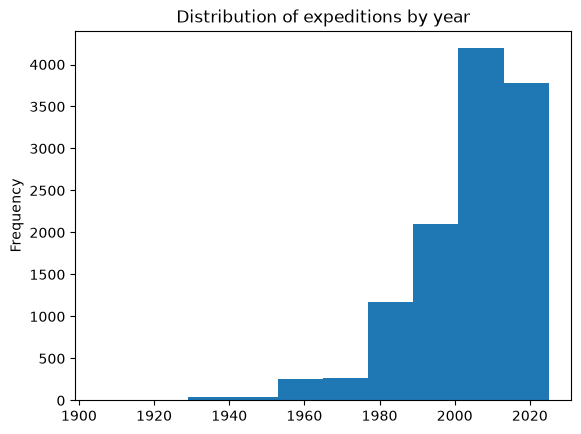

In [432]:
df.year.astype(int).plot(kind="hist")
plt.title("Distribution of expeditions by year")
plt.show()

- all the entries in the __year__ text column are numeric and should be converted to integer
- no outliers in the data, but significant right tail

#### Routes, ascents, and approach

In [433]:
df.loc[
  df.route4.notna(),
  ['route1', 'route2', 'route3', 'route4']]

,route1,route2,route3,route4
405,NE Pillar (to 5500m),N Face (to 5350m),E Ridge up; SE Face down,SE Face
510,"N Col-NE Ridge (up), SE Ridge-S Col (down)",N Col-NE Ridge,"S Col-SE Ridge (up), NE Ridge-N Col (down)",S Col-SE Ridge
822,SW Face,From Yalung Kang up; to Central and S Smts down,SW Face up; S Ridge-SW side down,South/Central Smts-S Ridge up; Yalung Kang down
2857,SW side-N Ridge,SW side-N Ridge up; N Ridge-Main Smt down,Y Kang/Main Smts-N Ridge up; S Ridge-S Smt down,S Smt-S Ridge up; N Ridge-Main/YK Smts down
5431,E Ridge (to 6200m),NE Face (to 6800m),NE Face (to 7500m),S Ridge (to 6400m)


In [434]:
df.route1 = df.route1.str.lower()
df.route2 = df.route2.str.lower()

In [435]:
df.route1.value_counts()[:10]

route1
sw ridge              1786
s col-se ridge        1354
nw side               1109
ne face                876
n col-ne ridge         791
w face                 470
ne ridge               455
se ridge               432
makalu la-nw ridge     295
nw ridge               290
Name: count, dtype: int64

In [436]:
df.route2.value_counts()[:10]

route2
s col-w face      26
w face            21
n face             8
s col-se ridge     8
ne ridge           7
sw ridge           6
n col-ne ridge     6
nw side            6
nw ridge           4
s face             4
Name: count, dtype: int64

The route variables in the expeditions dataset (__route1__, __route2__, __route3__, __route4__) are free-from, unstructured names given to the approach taken up to a peak. Values range from short, oft-repeated entries to unique idiosyncratic descriptions.

There is a case for creating a _routes_ table for the most common routes in the dataset.

In [437]:
# absolute and relative cardinality
print(f"Route absolute cardinality: {df.route1.nunique()}")
print(f"Route relative cardinality: {(df.route1.nunique() / df.shape[0]):.3f}")

Route absolute cardinality: 1282
Route relative cardinality: 0.108


In [438]:
route_counts = df.groupby(['peakid', 'route1'], as_index=False)['expid'].count()
print("Number of peakid/route combinations:", route_counts.shape[0])
print(f"Percentage of repeated combinations: {(100 * (route_counts.expid > 1).mean()):.3f}")

Number of peakid/route combinations: 2422
Percentage of repeated combinations: 21.263


In [439]:
route_counts.expid.describe()

count    2422.000000
mean        4.818745
std        54.681094
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max      1583.000000
Name: expid, dtype: float64

In [440]:
peak_routes = df.loc[df.route1.notna()].groupby('peakid', as_index=False).agg(
  expedition_count=pd.NamedAgg(column="expid", aggfunc="nunique"),
  route_count=pd.NamedAgg(column="route1", aggfunc="nunique"),
)
peak_routes["ratio"] = peak_routes.expedition_count / peak_routes.route_count

In [441]:
peak_routes.ratio.describe()

count    428.000000
mean       1.659464
std        2.534033
min        1.000000
25%        1.000000
50%        1.000000
75%        1.500000
max       34.061224
Name: ratio, dtype: float64

Notes:
- there are 2422 different peak ID/route combinations in the dataset (approximately 80% are unique)
- on average, a single peak route has been taken by 1.66 expeditions, but values are strongly skewed
- routes may be modeled as a __high-cardinality dimension__

Despite the high frequency of unique values, there is a significant subset of frequently recurring peak routes worthy of investigating. A dataset could be built to answer questions such as:
- which route is most frequently used?
- what is the average time-to-summit for each route?
- which route has the highest success rate?

In [442]:
ascent_columns = ['ascent1', 'ascent2', 'ascent3', 'ascent4']

In [443]:
df.loc[df.ascent4.notna(), ascent_columns]

,ascent1,ascent2,ascent3,ascent4
405,NaN,NaN,7th,8th
510,76th,76th,77th,78th
822,"27th-29th,33rd",30th,31st,32nd
2857,4th,5th,6th,7th


In [444]:
df.ascent1.value_counts(ascending=False)[:10]

ascent1
1st        277
2nd        120
3rd         75
4th         59
5th         41
1st,2nd     41
6th         38
7th         28
8th         28
9th         23
Name: count, dtype: int64

In [445]:
100 * df[ascent_columns].isna().sum() / df.shape[0]

ascent1    76.345537
ascent2    99.147967
ascent3    99.907204
ascent4    99.966256
dtype: float64

Notes:
- __ascent__ entries are non-atomic and inconsistently formatted
- there is a majority of missing values across all columns
- __these columns will not be included in models since not maintained for all peaks (per documentation)__

In [446]:
# absolute and relative cardinality
print(f"Approach absolute cardinality: {df.approach.nunique()}")
print(f"Approach relative cardinality: {(df.approach.nunique() / df.shape[0]):.3f}")

Approach absolute cardinality: 2661
Approach relative cardinality: 0.224


In [447]:
df.approach.isna().mean()

np.float64(0.5348405601484731)

In [448]:
df.approach.str.lower().value_counts(ascending=False)[:15]

approach
zhangmu->nyalam->tingri                 200
ktm->tingri->bc                         132
pangboche                               132
lukla->namche->pangboche->everest bc    115
kodari->tingri->bc                      111
khumbu valley                           102
lhasa->tingri                            75
kodari->tingri                           64
lukla->khumbu valley                     60
standard                                 59
lukla->namche->pangboche                 56
ktm->tingri->rongbuk bc                  54
zangmu->nyalam->tingri->bc               53
lukla->pangboche->everest bc             49
samagaon                                 42
Name: count, dtype: int64

Notes:
- __approach__ format is losely consistent: names separated by arrow symbols
- about half of approach values are missing
- Similarly to routes, approach has __high cardinality__ with a subset of values that are repeated more often. Analyses could be done around these _main_ approaches.

#### Agency and sponsor

In [449]:
df.loc[df.agency.notna() & df.sponsor.notna(), ['agency', 'sponsor']].head()

,agency,sponsor
11,Kunga,Australian Annapurna II Expedition
13,Sherpa Cooperative Trekking (SCT),British Annapurna II Winter Expedition
17,Remote Adventure,Azpeitia Annapurna II 86
18,Mountain Travel,1986 American Expedition to Annapurna II
19,Jai Himal Trekking,Okayama Climbing Club Annapurna II SE Face Exp...


In [450]:
df.agency.str.lower().value_counts(ascending=False)[:10]

agency
asian trekking        873
thamserku trekking    714
seven summit treks    511
himalayan guides      485
cosmo treks           301
monterosa treks       243
cho oyu trekking      207
prestige adventure    166
arun treks            151
everest parivar       151
Name: count, dtype: int64

In [451]:
print(f"Agency column cardinality: {df.agency.nunique()}")
print(f"Agency column missing value percentage: {df.agency.isna().mean():.3f}")

Agency column cardinality: 1004
Agency column missing value percentage: 0.136


In [452]:
df.sponsor.str.lower().value_counts(ascending=False)[:10]

sponsor
independent climber                 62
independent climber on everest      24
independent climber on cho oyu      16
independent team                    16
ama dablam expedition               15
swiss ama dablam expedition         11
international cho oyu expedition    11
international makalu expedition     10
japanese alpine club (jac)           9
cho oyu expedition                   9
Name: count, dtype: int64

In [453]:
print(f"Sponsor column cardinality: {df.sponsor.nunique()}")
print(f"Sponsor column missing value percentage: {df.sponsor.isna().mean():.3f}")

Sponsor column cardinality: 9574
Sponsor column missing value percentage: 0.069


Notes:
- both __agency__ and __sponsor__ columns are free-form text variables
- __agency__ has a lower cardinality and more repeated values than __sponsor__
- low percentage of missing values for both

Both __sponsor__ and __agency__ can be modeled as their own entities, and be topic for analyses such as:
- _do some agencies have a higher percentage of successful expeditions?_
- _do climbers remain loyal to given agencies?_

In [454]:
print(df.smttime.isna().sum())
df.smttime = pd.to_datetime(df.smttime, format="%H%M", errors="coerce")
df["summit_hr"] = df.smttime.dt.hour
df["summit_min"] = df.smttime.dt.minute
print(df.smttime.isna().sum())

6699
6706


With a few exceptions, __smttime__ column values are consistent and can be parsed to extract hour/minute details

In [455]:
df[["termnote", "othersmts", "campsites", "routememo", "accidents", "achievment"]].head()

,termnote,othersmts,campsites,routememo,accidents,achievment
0,NaN,Climbed Annapurna IV (ANN4-601-01),"BC(15/03,3350m),ABC(4575m),C1(5365m),C2(5800m)...",NaN,NaN,NaN
1,NaN,Climbed Annapurna IV (ANN4-693-02),"LowBC(25/09,3950m),BC(27/09,4650m),C1(27/09,53...","Summited after sunset, returned to C6 at 2:30 ...",Draslar frostbitten hands and feet,NaN
2,NaN,NaN,"BC(16/03,3300m),C1(21/03,4200m),C2(10/04,5000m...","Summit team of 3 left from C6, 2 returned from...",NaN,NaN
3,Abandoned at 7000m (on A-IV) due to bad weather,NaN,"BC(08/09,5190m),xxx(02/10,7000m)",Alpine-style ascent. Originally planned N Face...,NaN,NaN
4,Abandoned at 7160m due to high winds,NaN,"BC(3500m),ABC,Biv1,Biv2,Biv3,Biv4,Biv5,xxx(18/...",Paul Moores - 23 Oct 79\r\n\r\nAlan's illness ...,NaN,NaN


In [456]:
df[["termnote", "othersmts", "campsites", "routememo", "accidents", "achievment"]].isna().mean().round(3)

termnote      0.603
othersmts     0.813
campsites     0.035
routememo     0.141
accidents     0.709
achievment    0.918
dtype: float64

__The above variables are too unstructured to extract meaningful data from and will be left out of models.__

In [457]:
df.select_dtypes(include=[str]).columns

Index(['expid', 'peakid', 'year', 'route1', 'route2', 'route3', 'route4',
       'nation', 'leaders', 'sponsor', 'ascent1', 'ascent2', 'ascent3',
       'ascent4', 'countries', 'approach', 'termnote', 'othersmts',
       'campsites', 'routememo', 'accidents', 'achievment', 'agency',
       'primid'],
      dtype='str')

### Numeric variables
To assess the cleanliness of numeric variables, I mainly focus on prevalence of missing values, distribution and outlier detection. The aim is to make that values are present and within an expected range.

In [458]:
df.select_dtypes(include=["number"]).head()

,season,host,smtdays,totdays,termreason,highpoint,camps,rope,totmembers,smtmembers,mdeaths,tothired,smthired,hdeaths,chksum,summit_hr,summit_min
0,1,1,63,0,1,7937,6,0,10,2,0,9,1,0,2442047,15.0,30.0
1,3,1,27,31,1,7937,6,0,10,2,0,0,0,0,2445501,18.0,0.0
2,1,1,51,0,1,7937,5,0,6,1,0,8,0,0,2446797,20.0,30.0
3,3,1,24,27,4,7000,0,0,2,0,0,0,0,0,2448822,NaN,NaN
4,3,1,0,0,4,7160,0,0,3,0,0,0,0,0,2449204,NaN,NaN


In [459]:
df.select_dtypes(include=["number"]).isna().sum()

season           0
host             0
smtdays          0
totdays          0
termreason       0
highpoint        0
camps            0
rope             0
totmembers       0
smtmembers       0
mdeaths          0
tothired         0
smthired         0
hdeaths          0
chksum           0
summit_hr     6706
summit_min    6706
dtype: int64

In the case of the Expeditions dataset, several numerical columns merely represent lookup indices for external lookup tables. These will be treated as catefgorical variables in data models:
- __season__
- __host__
- __termreason__

Below, I confirm that values correspond to the IDs provided in the documentation.

In [460]:
assert set(df.season.unique()) == set(range(5))
assert set(df.host.unique()) == set(range(4))
assert set(df.termreason.unique()) == set(range(15))

In [461]:
df.highpoint.describe()

count    11854.000000
mean      7074.080479
std       1847.166856
min          0.000000
25%       6550.000000
50%       7152.000000
75%       8188.000000
max       8850.000000
Name: highpoint, dtype: float64

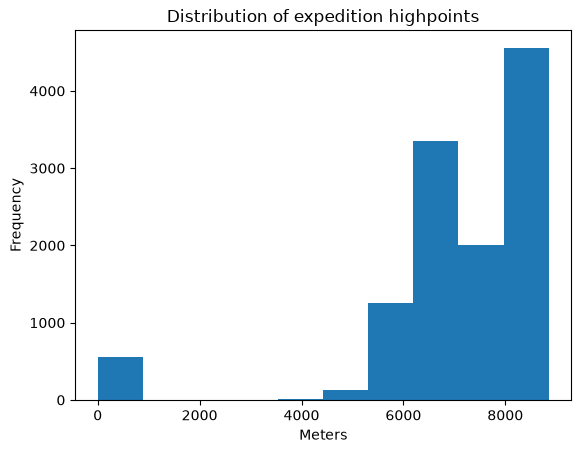

In [462]:
df.highpoint.plot(kind="hist")
plt.title("Distribution of expedition highpoints")
plt.xlabel("Meters")
plt.show()

In [463]:
df.loc[df.highpoint == 0, "termreason"].value_counts()

termreason
12    182
0     142
11     62
14     58
4      49
5      26
6      12
13      8
10      7
7       3
8       1
9       1
Name: count, dtype: int64

In [464]:
df.rope.describe()

count    11854.000000
mean       167.211996
std        660.835028
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       8700.000000
Name: rope, dtype: float64

In [465]:
df.camps.describe()

count    11854.000000
mean         2.257972
std          1.569480
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         34.000000
Name: camps, dtype: float64

The following variables are derived and will no be modeled:
- __totmembers__,
- __smtmember__,
- __mdeaths__,
- __tothired__,
- __smthired__,
- __hdeaths__

### Boolean variables

In [466]:
df.select_dtypes(include=[bool]).head()

,success1,success2,success3,success4,claimed,disputed,traverse,ski,parapente,nohired,o2used,o2none,o2climb,o2descent,o2sleep,o2medical,o2taken,o2unkwn,primrte,primmem
0,True,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False


In [467]:
df.select_dtypes(include=[bool]).isna().sum()

success1     0
success2     0
success3     0
success4     0
claimed      0
disputed     0
traverse     0
ski          0
parapente    0
nohired      0
o2used       0
o2none       0
o2climb      0
o2descent    0
o2sleep      0
o2medical    0
o2taken      0
o2unkwn      0
primrte      0
primmem      0
dtype: int64

In [468]:
df.select_dtypes(include=[bool]).mean()

success1     0.556943
success2     0.014594
success3     0.001097
success4     0.000422
claimed      0.002615
disputed     0.005315
traverse     0.010292
ski          0.016535
parapente    0.002025
nohired      0.309769
o2used       0.298718
o2none       0.690147
o2climb      0.268939
o2descent    0.013329
o2sleep      0.138772
o2medical    0.027923
o2taken      0.077780
o2unkwn      0.002446
primrte      0.020331
primmem      0.025224
dtype: float64

In [469]:
df.loc[df.o2used == df.o2none].shape

(132, 68)

In [470]:
df.loc[df.o2used == df.o2none, "o2unkwn"].value_counts()

o2unkwn
False    121
True      11
Name: count, dtype: int64

- Some inconsistencies in the O2 usage variables will need to be handled.

## Normalization

In [471]:
df.expid.head()

0    ANN260101
1    ANN269301
2    ANN273101
3    ANN278301
4    ANN279301
Name: expid, dtype: str

In [472]:
df.expid = df.expid.str.cat(df.year, sep="_")

In [473]:
assert df.expid.notna().all()
assert df.expid.is_unique

Expedition ID are built as concatenations of:
- __peak ID__ (e.g: ANN2)
- last 2 digits of __expedition year__ (e.g: 60)
- __expedition season__ (e.g: 1)
- __expedition number__ (e.g: 01)

This construct is susceptible to conflict in the (infrequent but plausible) event of two expeditions to the same peak in the same season taking place one century appart. Uniqueness is easily ensured by appending the full year (yyyy) to the ID values.

In [474]:
df.head()

,expid,peakid,year,season,host,route1,route2,route3,route4,nation,...,agency,comrte,stdrte,primrte,primmem,primref,primid,chksum,summit_hr,summit_min
0,ANN260101_1960,ANN2,1960,1,1,nw ridge-w ridge,NaN,NaN,NaN,UK,...,NaN,None,None,False,False,None,NaN,2442047,15.0,30.0
1,ANN269301_1969,ANN2,1969,3,1,nw ridge-w ridge,NaN,NaN,NaN,Yugoslavia,...,NaN,None,None,False,False,None,NaN,2445501,18.0,0.0
2,ANN273101_1973,ANN2,1973,1,1,w ridge-n face,NaN,NaN,NaN,Japan,...,NaN,None,None,False,False,None,NaN,2446797,20.0,30.0
3,ANN278301_1978,ANN2,1978,3,1,n face-w ridge,NaN,NaN,NaN,UK,...,NaN,None,None,False,False,None,NaN,2448822,NaN,NaN
4,ANN279301_1979,ANN2,1979,3,1,n face-w ridge,nw ridge of a-iv,NaN,NaN,UK,...,NaN,None,None,False,False,None,NaN,2449204,NaN,NaN


In [475]:
df_routes = pd.concat([
  df.loc[df.route1.notna(), ['peakid', 'route1']].rename({'route1': 'name'}, axis=1),
  df.loc[df.route2.notna(), ['peakid', 'route2']].rename({'route2': 'name'}, axis=1)
]).drop_duplicates(ignore_index=True).reset_index(names="id")

In [476]:
df_routes.head()

,id,peakid,name
0,0,ANN2,nw ridge-w ridge
1,1,ANN2,w ridge-n face
2,2,ANN2,n face-w ridge
3,3,ANN2,se spur (to 6000m)
4,4,ANN2,s ridge/se face


Below, I unpivot the dataset so that each route/ascent appears on its own row as opposed to columns. This leads to the creation of two data tables:
1. __routes__: one row for each peakid/route combination; each row is assigned its own id
2. __ascent__: every row represents an ascent (an expedition climb along a particular route) and its binary outcome

In [488]:
df_ascents = pd.concat([
  df.assign(route_number=1).loc[df.route1.notna(), ['expid', 'peakid', 'route_number', 'route1', 'success1']].rename({'route1': 'name', 'success1': 'success'}, axis=1),
  df.assign(route_number=2).loc[df.route2.notna(), ['expid', 'peakid', 'route_number', 'route2', 'success2']].rename({'route2': 'name', 'success2': 'success'}, axis=1),
  df.assign(route_number=3).loc[df.route3.notna(), ['expid', 'peakid', 'route_number', 'route3', 'success3']].rename({'route3': 'name', 'success3': 'success'}, axis=1),
  df.assign(route_number=4).loc[df.route4.notna(), ['expid', 'peakid', 'route_number', 'route4', 'success4']].rename({'route4': 'name', 'success4': 'success'}, axis=1)
]).drop_duplicates(ignore_index=True).reset_index(names="id")

In [489]:
df_ascents.head()

,id,expid,peakid,route_number,name,success
0,0,ANN260101_1960,ANN2,1,nw ridge-w ridge,True
1,1,ANN269301_1969,ANN2,1,nw ridge-w ridge,True
2,2,ANN273101_1973,ANN2,1,w ridge-n face,True
3,3,ANN278301_1978,ANN2,1,n face-w ridge,False
4,4,ANN279301_1979,ANN2,1,n face-w ridge,False


In [490]:
df_ascents.route_number.value_counts()

route_number
1    11671
2      371
3       30
4        5
Name: count, dtype: int64

In [491]:
df_ascents = (df_ascents
              .merge(df_routes.rename({"id": "route_id"}, axis=1), on=["peakid", "name"])
              .drop(["peakid", "name"], axis=1)
)

In [492]:
df_ascents.head()

,id,expid,route_number,success,route_id
0,0,ANN260101_1960,1,True,0
1,1,ANN269301_1969,1,True,0
2,2,ANN273101_1973,1,True,1
3,3,ANN278301_1978,1,False,2
4,4,ANN279301_1979,1,False,2


- Create a table for peak routes by unioning unique values from __route1__, __route2__, __route3__, and __route4__
- Create a table for expedition ascents by combining __route ID__ and __success__

In [499]:
df.groupby('peakid', as_index=False).approach.nunique().sort_values('approach', ascending=False)[:10]

,peakid,approach
1,AMAD,307
91,EVER,300
256,MANA,189
68,DHA1,158
49,CHOY,156
254,MAKA,128
19,BARU,128
133,HIML,89
7,ANN1,85
176,KANG,81


In [501]:
df.groupby('approach', as_index=False).peakid.nunique().sort_values('peakid', ascending=False)[:20]

,approach,peakid
2268,See route details,18
2269,See route notes,17
0,(see route notes),16
1425,Lukla->Khumbu Valley,10
1140,Khumbu Valley,9
1593,Lukla->Namche->Pangboche,7
2232,Rolwaling Valley,7
1325,Lukla,7
1882,Modi Khola,6
858,Helicopter to BC,6


#### ROUTE
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| PEAK_ID | INT | FK |
| NAME | TEXT | NOT NULL |

#### ASCENT
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| EXPEDITION_ID | INT | FK |
| ROUTE_ID | INT | FK |
| ROUTE_NUMBER | INT ||
| SUCCESS | BOOL ||

#### EXPEDITION
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | TEXT    | PK |
| PEAK_ID  | INT    | FK |
| YEAR  | INT    ||
| SEASON  | INT    | FK |
| HOST  | INT    | FK |
| NATION  | INT    | FK |
| SPONSOR  | INT    | FK |
| AGENCY  | INT    | FK |
| CLAIMED  | BOOL    | |
| DISPUTED  | BOOL    | |
| APPROACH  | TEXT    | |
| BASECAMP_DATE  | DATE    | |
| SUMMIT_DATE  | DATE    | |
| SUMMIT_HOUR  | INT    | |
| SUMMIT_MINUTE  | INT    | |
| TERMINATION_DATE  | DATE    | |
| TERMINATION_REASON  | INT    | FK |
| TERMINATION_NOTE  | INT    | FK |
| HIGHPOINT  | INT    | |
| TRAVERSE  | BOOL    | |
| SKI  | BOOL    | |
| PARAPENTE  | BOOL    | |
| CAMPS  | INT    | |
| ROPE  | INT    | |
| NOHIRED  | BOOL    | |
| O2_USED  | BOOL    | |
| O2_KNOWN  | BOOL    | |
| O2_CLIMB  | BOOL    | |
| O2_DESCENT  | BOOL    | |
| O2_SLEEP  | BOOL    | |
| O2_MEDICAL  | BOOL    | |
| O2_TAKEN  | BOOL    | |
| COMMERCIAL_ROUTE  | BOOL    | |
| STANDARD_ROUTE  | BOOL    | |
| CHKSUM | TEXT    | |